In [48]:
!zip -r unetpp_aspect10_mod_3_outputs.zip /content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs

  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/ (stored 0%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/validation_metrics_summary.csv (deflated 39%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_per_image.png (deflated 17%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/dataset_split_manifest.csv (deflated 91%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_summary.csv (deflated 39%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/test_metrics_per_image.csv (deflated 42%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnablekernel_outputs/validation_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_aspect10_mod3_learnabl

In [49]:
import os
import glob
import random
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from google.colab import drive

SEED = 42
IMG_SIZE = (256, 256)
BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 0.0003
BOUNDARY_TOLERANCE_PX = 2
PREDICTION_THRESHOLD = 0.5
IMAGE_DIR = '/content/ASPECT-10/ASPECT-10/IMAGES'
MASK_DIR = '/content/ASPECT-10/ASPECT-10/Binary_Mask'
OUTPUT_DIR = '/content/drive/MyDrive/resunet_aspect10_colab_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)


for directory, label in ((IMAGE_DIR, 'IMAGE_DIR'), (MASK_DIR, 'MASK_DIR')):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f'{label} does not exist: {directory}. Update IMAGE_DIR and MASK_DIR in this cell.')
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
physical_gpus = tf.config.list_physical_devices('GPU')
for gpu in physical_gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as exc:
        print('GPU memory growth setting:', exc)
print('TensorFlow:', tf.__version__)
print('Visible GPUs:', physical_gpus if physical_gpus else 'None; using available CPU')
print('Output directory:', OUTPUT_DIR)
VALID_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def list_image_files(directory):
    files = []
    for ext in VALID_EXTENSIONS:
        files.extend(glob.glob(os.path.join(directory, f'*{ext}')))
        files.extend(glob.glob(os.path.join(directory, f'*{ext.upper()}')))
    return sorted(set(files))

def get_pairs(image_dir, mask_dir):
    image_paths = list_image_files(image_dir)
    mask_paths = list_image_files(mask_dir)
    if not image_paths or not mask_paths:
        raise RuntimeError('No images or masks found; check IMAGE_DIR and MASK_DIR.')
    image_map = {}
    mask_map = {}
    for path in image_paths:
        image_map.setdefault(Path(path).stem, []).append(path)
    for path in mask_paths:
        mask_map.setdefault(Path(path).stem, []).append(path)
    duplicate_images = {k: v for k, v in image_map.items() if len(v) != 1}
    duplicate_masks = {k: v for k, v in mask_map.items() if len(v) != 1}
    if duplicate_images or duplicate_masks:
        raise ValueError(f'Duplicate filename stems found. Images: {list(duplicate_images)[:5]}; masks: {list(duplicate_masks)[:5]}')
    missing_masks = sorted(set(image_map) - set(mask_map))
    missing_images = sorted(set(mask_map) - set(image_map))
    if missing_masks or missing_images:
        raise ValueError(f'Image-mask pairing is incomplete. Images without masks: {missing_masks[:10]}; masks without images: {missing_images[:10]}')
    return [(image_map[stem][0], mask_map[stem][0]) for stem in sorted(image_map)]

def load_image_mask(img_path, mask_path):

    def path_string(path):
        if isinstance(path, (bytes, np.bytes_)):
            return path.decode('utf-8')
        if isinstance(path, np.ndarray):
            path = path.item()
        if isinstance(path, (bytes, np.bytes_)):
            return path.decode('utf-8')
        return os.fspath(path)
    img_path = path_string(img_path)
    mask_path = path_string(mask_path)
    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Could not read image: {img_path}')
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_AREA)
    image = image.astype(np.float32) / 255.0
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f'Could not read mask: {mask_path}')
    mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)[..., np.newaxis]
    return (image, mask)

def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(load_image_mask, [img_path, mask_path], [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return (image, mask)

def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image, mask = (tf.image.flip_left_right(image), tf.image.flip_left_right(mask))
    if tf.random.uniform(()) > 0.5:
        image, mask = (tf.image.flip_up_down(image), tf.image.flip_up_down(mask))
    return (image, mask)

def make_dataset(sample_pairs, training=False):
    image_paths = [pair[0] for pair in sample_pairs]
    mask_paths = [pair[1] for pair in sample_pairs]
    ds = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        ds = ds.shuffle(buffer_size=len(sample_pairs), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(tf_load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
pairs = get_pairs(IMAGE_DIR, MASK_DIR)
if len(pairs) < 10:
    raise ValueError(f'At least 10 paired samples are needed for an 80/10/10 split; found {len(pairs)}.')
train_pairs, holdout_pairs = train_test_split(pairs, test_size=0.2, random_state=SEED, shuffle=True)
val_pairs, test_pairs = train_test_split(holdout_pairs, test_size=0.5, random_state=SEED, shuffle=True)

def sample_keys(sample_pairs):
    return {os.path.abspath(pair[0]) for pair in sample_pairs}
train_keys, val_keys, test_keys = map(sample_keys, (train_pairs, val_pairs, test_pairs))
assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)
assert train_keys | val_keys | test_keys == sample_keys(pairs)
assert len(train_pairs) + len(val_pairs) + len(test_pairs) == len(pairs)
manifest_rows = []
for split_name, split_pairs in (('train', train_pairs), ('validation', val_pairs), ('test', test_pairs)):
    for image_path, mask_path in split_pairs:
        manifest_rows.append({'split': split_name, 'image': image_path, 'mask': mask_path, 'image_filename': Path(image_path).name})
manifest_path = os.path.join(OUTPUT_DIR, 'dataset_split_manifest.csv')
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)
train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs)
print(f'Total paired samples: {len(pairs)}')
print(f'Train: {len(train_pairs)} ({len(train_pairs) / len(pairs):.1%})')
print(f'Validation: {len(val_pairs)} ({len(val_pairs) / len(pairs):.1%})')
print(f'Test: {len(test_pairs)} ({len(test_pairs) / len(pairs):.1%})')
print('Saved split manifest:', manifest_path)


TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Output directory: /content/drive/MyDrive/resunet_aspect10_colab_outputs
Total paired samples: 30
Train: 24 (80.0%)
Validation: 3 (10.0%)
Test: 3 (10.0%)
Saved split manifest: /content/drive/MyDrive/resunet_aspect10_colab_outputs/dataset_split_manifest.csv


In [50]:
def residual_block_initial(x, filters, strides=(1, 1), name='res_initial'):
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(x)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
    shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

def residual_block(x, filters, strides=(1, 1), name='res_block'):
    input_channels = x.shape[-1]
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn1')(x)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu1')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv1')(y)
    y = tf.keras.layers.BatchNormalization(name=f'{name}_bn2')(y)
    y = tf.keras.layers.Activation('relu', name=f'{name}_relu2')(y)
    y = tf.keras.layers.Conv2D(filters, 3, strides=strides[1], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_conv2')(y)
    if strides[0] != 1 or input_channels != filters:
        shortcut = tf.keras.layers.Conv2D(filters, 1, strides=strides[0], padding='same', use_bias=False, kernel_initializer='he_normal', name=f'{name}_shortcut_conv')(x)
        shortcut = tf.keras.layers.BatchNormalization(name=f'{name}_shortcut_bn')(shortcut)
    else:
        shortcut = x
    return tf.keras.layers.Add(name=f'{name}_add')([shortcut, y])

def build_resunet(input_shape=(256, 256, 3), filters=(64, 128, 256, 512)):
    inputs = tf.keras.Input(shape=input_shape, name='image')
    e0 = residual_block_initial(inputs, filters[0], name='encoder_block0')
    e1 = residual_block(e0, filters[1], strides=(2, 1), name='encoder_block1')
    e2 = residual_block(e1, filters[2], strides=(2, 1), name='encoder_block2')
    e3 = residual_block(e2, filters[3], strides=(2, 1), name='encoder_block3')
    bridge = residual_block(e3, filters[3] * 2, strides=(2, 1), name='bridge')
    d3 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name='decoder_up3')(bridge)
    d3 = tf.keras.layers.Concatenate(name='decoder_concat3')([d3, e3])
    d3 = residual_block(d3, filters[3], name='decoder_block3')
    d2 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name='decoder_up2')(d3)
    d2 = tf.keras.layers.Concatenate(name='decoder_concat2')([d2, e2])
    d2 = residual_block(d2, filters[2], name='decoder_block2')
    d1 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name='decoder_up1')(d2)
    d1 = tf.keras.layers.Concatenate(name='decoder_concat1')([d1, e1])
    d1 = residual_block(d1, filters[1], name='decoder_block1')
    d0 = tf.keras.layers.UpSampling2D(size=(2, 2), interpolation='bilinear', name='decoder_up0')(d1)
    d0 = tf.keras.layers.Concatenate(name='decoder_concat0')([d0, e0])
    d0 = residual_block(d0, filters[0], name='decoder_block0')
    logits = tf.keras.layers.Conv2D(1, 1, padding='same', activation=None, name='segmentation_logits')(d0)
    return tf.keras.Model(inputs=inputs, outputs=logits, name='ResUNet')

def _binary_from_logits(y_true, y_pred):
    y_true = tf.cast(y_true >= 0.5, tf.float32)
    y_pred = tf.cast(y_pred >= 0.0, tf.float32)
    return (y_true, y_pred)

def binary_accuracy_logits(y_true, y_pred):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    return tf.reduce_mean(tf.cast(tf.equal(y_true, y_pred), tf.float32))

def dice_coef_logits(y_true, y_pred, smooth=1e-07):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) + smooth)

def iou_coef_logits(y_true, y_pred, smooth=1e-07):
    y_true, y_pred = _binary_from_logits(y_true, y_pred)
    y_true = tf.reshape(y_true, [-1])
    y_pred = tf.reshape(y_pred, [-1])
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection
    return (intersection + smooth) / (union + smooth)
PAPER_FILTERS = (64, 128, 256, 512)
model = build_resunet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3), filters=PAPER_FILTERS)
print('Encoder filters:', PAPER_FILTERS)
print('Bridge filters:', PAPER_FILTERS[-1] * 2)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE), loss=tf.keras.losses.BinaryCrossentropy(from_logits=True), metrics=[binary_accuracy_logits, dice_coef_logits, iou_coef_logits])
model.summary()


Encoder filters: (64, 128, 256, 512)
Bridge filters: 1024


Model: "ResUNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 256, 256,  │          0 │ -                 │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │      1,728 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        192 │ image[0][0]       │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_rel… │ (None, 256, 256,  │          0 │ encoder_block0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_sho… │ (None, 256, 256,  │        256 │ encoder_block0_s… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_con… │ (None, 256, 256,  │     36,864 │ encoder_block0_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block0_add  │ (None, 256, 256,  │          0 │ encoder_block0_s… │
│ (Add)               │ 64)               │            │ encoder_block0_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn1  │ (None, 256, 256,  │        256 │ encoder_block0_a… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 256, 256,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │     73,728 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_bn2  │ (None, 128, 128,  │        512 │ encoder_block1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │      8,192 │ encoder_block0_a… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_rel… │ (None, 128, 128,  │          0 │ encoder_block1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_sho… │ (None, 128, 128,  │        512 │ encoder_block1_s… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_con… │ (None, 128, 128,  │    147,456 │ encoder_block1_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_block1_add  │ (None, 128, 128,  │          0 │ encoder_block1_s

 Total params: 33,152,961 (126.47 MB)

 Trainable params: 33,133,505 (126.39 MB)

 Non-trainable params: 19,456 (76.00 KB)

Epoch 1/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - binary_accuracy_logits: 0.8492 - dice_coef_logits: 0.9121 - iou_coef_logits: 0.8464 - loss: 0.4415
Epoch 1: val_dice_coef_logits improved from None to 0.96654, saving model to /content/drive/MyDrive/resunet_aspect10_colab_outputs/best_resunet.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/resunet_aspect10_colab_outputs/best_resunet.weights.h5
24/24 ━━━━━━━━━━━━━━━━━━━━ 107s 548ms/step - binary_accuracy_logits: 0.9055 - dice_coef_logits: 0.9473 - iou_coef_logits: 0.9033 - loss: 0.2762 - val_binary_accuracy_logits: 0.9354 - val_dice_coef_logits: 0.9665 - val_iou_coef_logits: 0.9354 - val_loss: 31.4002 - learning_rate: 3.0000e-04
Epoch 2/50
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - binary_accuracy_logits: 0.9399 - dice_coef_logits: 0.9682 - iou_coef_logits: 0.9386 - loss: 0.1645
Epoch 2: val_dice_coef_logits improved from 0.96654 to 0.96662, saving model to /content/drive/MyDrive/resunet_aspect10_colab_outputs/be

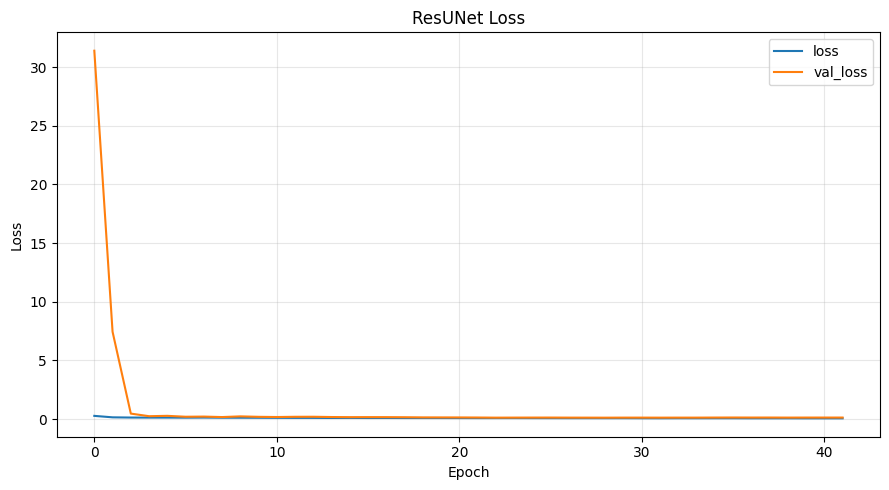

Saved: /content/drive/MyDrive/resunet_aspect10_colab_outputs/training_loss.png


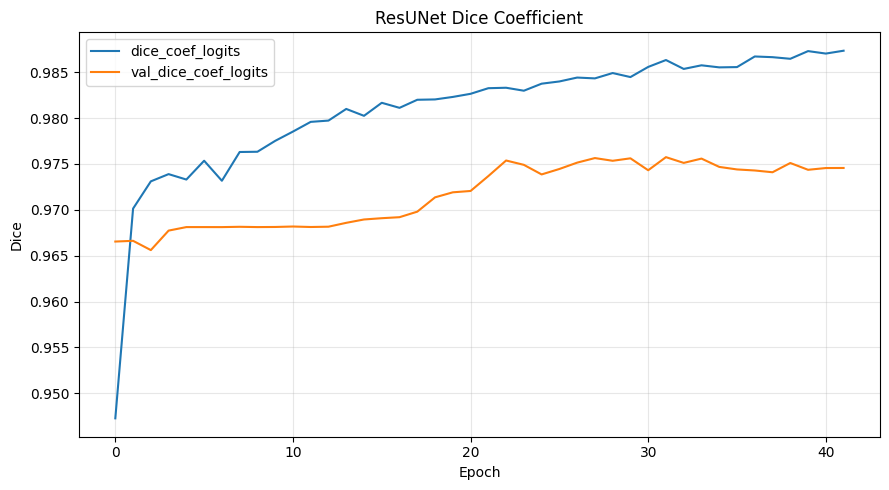

Saved: /content/drive/MyDrive/resunet_aspect10_colab_outputs/training_dice.png


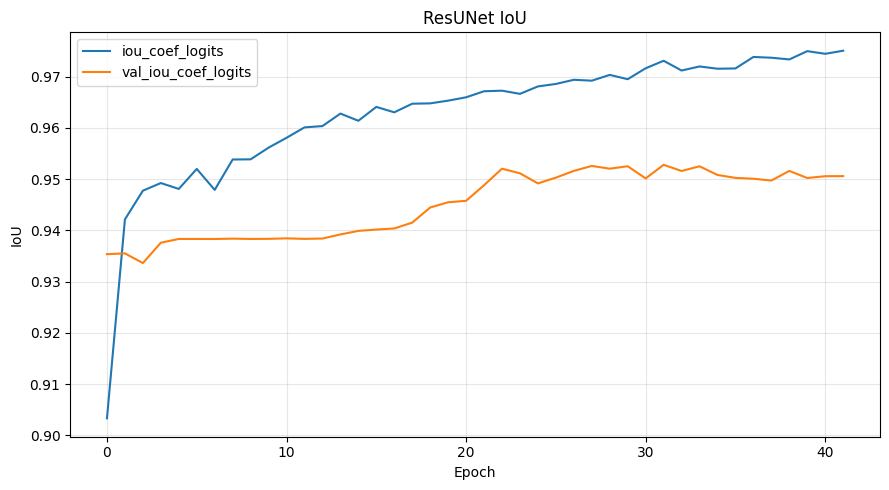

Saved: /content/drive/MyDrive/resunet_aspect10_colab_outputs/training_iou.png


In [51]:
BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, 'best_resunet.weights.h5')
callbacks = [tf.keras.callbacks.ModelCheckpoint(BEST_WEIGHTS_PATH, monitor='val_dice_coef_logits', mode='max', save_best_only=True, save_weights_only=True, verbose=1), tf.keras.callbacks.EarlyStopping(monitor='val_dice_coef_logits', mode='max', patience=10, restore_best_weights=True, verbose=1), tf.keras.callbacks.ReduceLROnPlateau(monitor='val_dice_coef_logits', mode='max', factor=0.5, patience=4, min_lr=1e-06, verbose=1), tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, 'training_log.csv'))]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, verbose=1)
if not os.path.isfile(BEST_WEIGHTS_PATH):
    raise FileNotFoundError(f'Best weights were not created: {BEST_WEIGHTS_PATH}')
model.load_weights(BEST_WEIGHTS_PATH)
history_df = pd.DataFrame(history.history)
history_df.to_csv(os.path.join(OUTPUT_DIR, 'training_history.csv'), index_label='epoch')
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, 'resunet_best.keras')
model.save(FINAL_MODEL_PATH)
print('Saved best-validation model:', FINAL_MODEL_PATH)
print('Saved best weights:', BEST_WEIGHTS_PATH)

def plot_history(history_dict, keys, title, ylabel, output_name):
    plt.figure(figsize=(9, 5))
    plotted = False
    for key in keys:
        if key in history_dict:
            plt.plot(history_dict[key], label=key)
            plotted = True
    if plotted:
        plt.title(title)
        plt.xlabel('Epoch')
        plt.ylabel(ylabel)
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plot_path = os.path.join(OUTPUT_DIR, output_name)
        plt.savefig(plot_path, dpi=160, bbox_inches='tight')
        plt.show()
        print('Saved:', plot_path)
    else:
        plt.close()
plot_history(history.history, ['loss', 'val_loss'], 'ResUNet Loss', 'Loss', 'training_loss.png')
plot_history(history.history, ['dice_coef_logits', 'val_dice_coef_logits'], 'ResUNet Dice Coefficient', 'Dice', 'training_dice.png')
plot_history(history.history, ['iou_coef_logits', 'val_iou_coef_logits'], 'ResUNet IoU', 'IoU', 'training_iou.png')


Validation 1/3: Agg_Rounded_Black_M_HLC_03.jpg
Validation 2/3: Agg_Crushed_Clear_M_GLC_03.jpg
Validation 3/3: Agg_Crushed_Red_S_GLC_03.jpg

VALIDATION METRICS — MACRO-AVERAGE OVER 3 IMAGES
IoU                     : 0.9528 ± 0.0220
Recall                  : 0.9820 ± 0.0158
Precision               : 0.9696 ± 0.0088
Dice_Coefficient        : 0.9757 ± 0.0116
Boundary_F1             : 0.6968 ± 0.1097
Boundary_Recall         : 0.5745 ± 0.1487
Boundary_Precision      : 0.9178 ± 0.0308


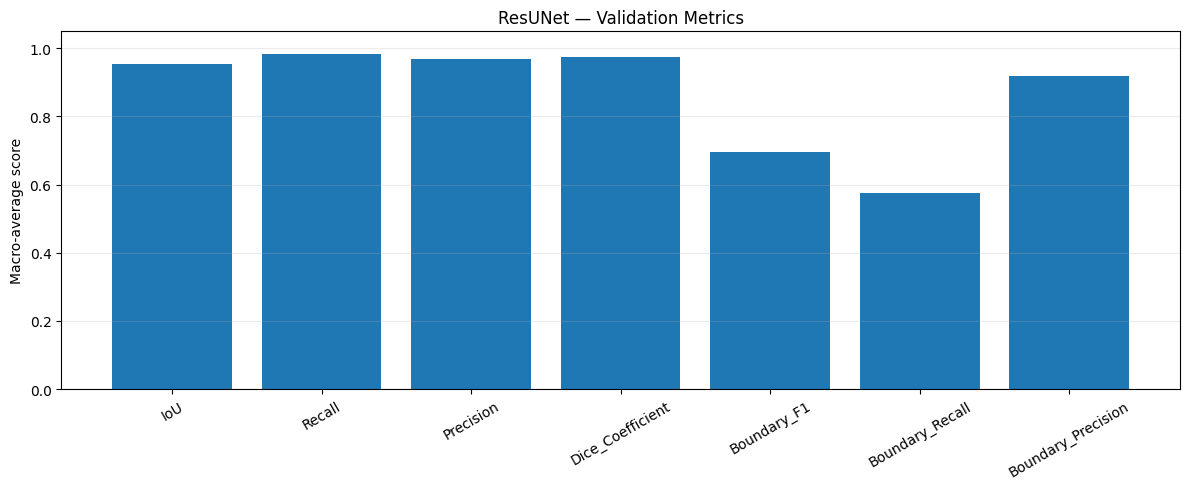

Test 1/3: LightAgg_Black_M_HTC_01.jpg
Test 2/3: Agg_Crushed_Red_S_GLC_01.jpg
Test 3/3: Agg_Crushed_Green_M_GLC_01.jpg

TEST METRICS — MACRO-AVERAGE OVER 3 IMAGES
IoU                     : 0.9582 ± 0.0151
Recall                  : 0.9858 ± 0.0048
Precision               : 0.9715 ± 0.0114
Dice_Coefficient        : 0.9786 ± 0.0078
Boundary_F1             : 0.7180 ± 0.0839
Boundary_Recall         : 0.5960 ± 0.1064
Boundary_Precision      : 0.9123 ± 0.0455


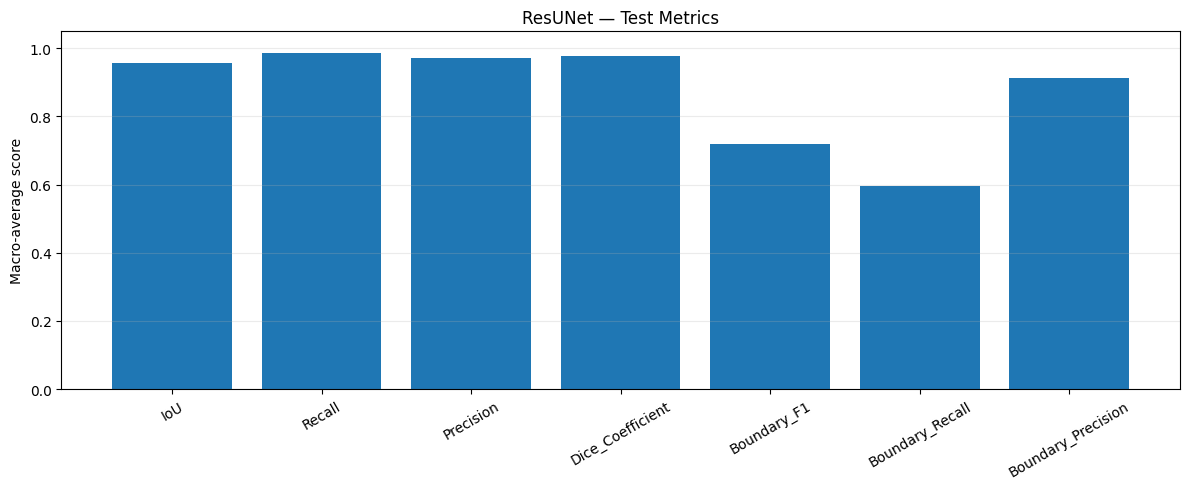


Test images: 3
Saved test predicted masks: /content/drive/MyDrive/resunet_aspect10_colab_outputs/test_predicted_masks
Saved test comparison previews: /content/drive/MyDrive/resunet_aspect10_colab_outputs/test_prediction_previews
All results: /content/drive/MyDrive/resunet_aspect10_colab_outputs


In [52]:
METRIC_COLUMNS = ['IoU', 'Recall', 'Precision', 'Dice_Coefficient', 'Boundary_F1', 'Boundary_Recall', 'Boundary_Precision']

def safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0

def binary_segmentation_metrics(y_true, y_pred):
    gt = np.asarray(y_true, dtype=bool)
    pred = np.asarray(y_pred, dtype=bool)
    tp = int(np.logical_and(gt, pred).sum())
    fp = int(np.logical_and(~gt, pred).sum())
    fn = int(np.logical_and(gt, ~pred).sum())
    precision = safe_divide(tp, tp + fp)
    recall = safe_divide(tp, tp + fn)
    iou = safe_divide(tp, tp + fp + fn)
    dice = safe_divide(2 * tp, 2 * tp + fp + fn)
    gt_u8 = gt.astype(np.uint8)
    pred_u8 = pred.astype(np.uint8)
    erode_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    gt_boundary = (gt_u8 - cv2.erode(gt_u8, erode_kernel, iterations=1)).astype(bool)
    pred_boundary = (pred_u8 - cv2.erode(pred_u8, erode_kernel, iterations=1)).astype(bool)
    kernel_size = 2 * BOUNDARY_TOLERANCE_PX + 1
    tolerance_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
    gt_dilated = cv2.dilate(gt_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    pred_dilated = cv2.dilate(pred_boundary.astype(np.uint8), tolerance_kernel, iterations=1).astype(bool)
    matched_pred = int(np.logical_and(pred_boundary, gt_dilated).sum())
    matched_gt = int(np.logical_and(gt_boundary, pred_dilated).sum())
    boundary_precision = safe_divide(matched_pred, int(pred_boundary.sum()))
    boundary_recall = safe_divide(matched_gt, int(gt_boundary.sum()))
    boundary_f1 = safe_divide(2 * boundary_precision * boundary_recall, boundary_precision + boundary_recall)
    return {'IoU': iou, 'Recall': recall, 'Precision': precision, 'Dice_Coefficient': dice, 'Boundary_F1': boundary_f1, 'Boundary_Recall': boundary_recall, 'Boundary_Precision': boundary_precision}

def evaluate_split(split_name, sample_pairs, save_predictions=False):
    rows = []
    prediction_dir = os.path.join(OUTPUT_DIR, f'{split_name.lower()}_predicted_masks')
    preview_dir = os.path.join(OUTPUT_DIR, f'{split_name.lower()}_prediction_previews')
    if save_predictions:
        os.makedirs(prediction_dir, exist_ok=True)
        os.makedirs(preview_dir, exist_ok=True)
    for idx, (image_path, mask_path) in enumerate(sample_pairs, start=1):
        image, gt_mask = load_image_mask(image_path, mask_path)
        logits = model.predict(image[np.newaxis, ...], verbose=0)[0, ..., 0]
        pred_mask = tf.math.sigmoid(logits).numpy() >= PREDICTION_THRESHOLD
        gt_binary = gt_mask[..., 0] >= 0.5
        scores = binary_segmentation_metrics(gt_binary, pred_mask)
        rows.append({'image_name': Path(image_path).name, **scores})
        if save_predictions:
            stem = Path(image_path).stem
            mask_path_out = os.path.join(prediction_dir, f'{stem}_prediction.png')
            if not cv2.imwrite(mask_path_out, pred_mask.astype(np.uint8) * 255):
                raise IOError(f'Could not save predicted mask: {mask_path_out}')
            overlay = image.copy()
            overlay[pred_mask] = 0.55 * overlay[pred_mask] + 0.45 * np.array([1.0, 0.0, 0.0])
            fig, axes = plt.subplots(1, 4, figsize=(14, 4))
            axes[0].imshow(image)
            axes[0].set_title('Image')
            axes[1].imshow(gt_binary, cmap='gray')
            axes[1].set_title('Ground truth')
            axes[2].imshow(pred_mask, cmap='gray')
            axes[2].set_title('Prediction')
            axes[3].imshow(np.clip(overlay, 0, 1))
            axes[3].set_title('Overlay')
            for ax in axes:
                ax.axis('off')
            fig.suptitle(Path(image_path).name)
            plt.tight_layout()
            preview_path = os.path.join(preview_dir, f'{stem}_comparison.png')
            fig.savefig(preview_path, dpi=140, bbox_inches='tight')
            plt.close(fig)
        print(f'{split_name} {idx}/{len(sample_pairs)}: {Path(image_path).name}')
    if len(rows) != len(sample_pairs):
        raise RuntimeError(f'Expected {len(sample_pairs)} predictions for {split_name}, produced {len(rows)}.')
    result_df = pd.DataFrame(rows)
    result_df.to_csv(os.path.join(OUTPUT_DIR, f'{split_name.lower()}_metrics_per_image.csv'), index=False)
    means = result_df[METRIC_COLUMNS].mean()
    stds = result_df[METRIC_COLUMNS].std(ddof=1).fillna(0.0) if len(result_df) > 1 else means * 0.0
    summary_df = pd.DataFrame({'metric': METRIC_COLUMNS, 'mean_score': [float(means[m]) for m in METRIC_COLUMNS], 'std_score': [float(stds[m]) for m in METRIC_COLUMNS], 'n_images': [len(result_df)] * len(METRIC_COLUMNS)})
    summary_df.to_csv(os.path.join(OUTPUT_DIR, f'{split_name.lower()}_metrics_summary.csv'), index=False)
    print(f'\n{split_name.upper()} METRICS — MACRO-AVERAGE OVER {len(result_df)} IMAGES')
    for metric in METRIC_COLUMNS:
        print(f'{metric:<24}: {means[metric]:.4f} ± {stds[metric]:.4f}')
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.bar(METRIC_COLUMNS, [float(means[m]) for m in METRIC_COLUMNS])
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Macro-average score')
    ax.set_title(f'ResUNet — {split_name} Metrics')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.25)
    fig.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, f'{split_name.lower()}_metrics_summary.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return result_df
val_results = evaluate_split('Validation', val_pairs, save_predictions=False)
test_results = evaluate_split('Test', test_pairs, save_predictions=True)
test_prediction_dir = os.path.join(OUTPUT_DIR, 'test_predicted_masks')
predicted_mask_files = list_image_files(test_prediction_dir)
if len(predicted_mask_files) != len(test_pairs):
    raise RuntimeError(f'Expected {len(test_pairs)} saved test masks, found {len(predicted_mask_files)}.')
print('\nTest images:', len(test_pairs))
print('Saved test predicted masks:', test_prediction_dir)
print('Saved test comparison previews:', os.path.join(OUTPUT_DIR, 'test_prediction_previews'))
print('All results:', OUTPUT_DIR)
